# Actividad 4.2: Procesos estocásticos y generador de melodías mediante cadenas de Markov

**Curso:** Desarrollo de aplicaciones avanzadas de ciencias computacionales (Gpo 570)  
**Profesor:** Luis Ricardo Peña Llamas  
**Alumno:** Fernando Daniel Monroy Sánchez (A01750536)  
**Fecha:** 15 de octubre de 2026  

---

## 1. Introducción

Una melodía se define acústicamente como una sucesión temporal de notas con alturas y duraciones determinadas. Una cuestión fundamental en el análisis de sistemas y la teoría de la información es si dicha secuencia puede formalizarse como un **proceso estocástico**.

Un proceso estocástico es una colección de variables aleatorias $\{X_t : t \in T\}$ indexadas por un conjunto de tiempo $T$. En la música tonal occidental, las transiciones entre notas no ocurren de manera caótica ni puramente determinista: están gobernadas por reglas de tensión armónica, tendencias de resolución y jerarquías tonales. Por ende, la música constituye un proceso estocástico con estructura de dependencia temporal.

El objetivo principal de esta práctica consiste en:
1. Diseñar una cadena de Markov que modele las probabilidades de transición entre notas de la escala diatónica de Re Mayor y acordes armónicos.
2. Representar y validar rigurosamente la matriz de transición estocástica.
3. Implementar un generador pseudoaleatorio de transiciones melódicas y acústicas.
4. Sintetizar acústicamente cada tono empleando frecuencia fundamental y duración variable con suavizado de envolvente ADSR para prevenir distorsión.
5. Analizar la convergencia hacia la distribución estacionaria mediante las ecuaciones de Chapman Kolmogorov.
6. Realizar una reflexión epistemológica profunda sobre patrones repetitivos, aprendizaje de estilos y limitaciones intrínsecas del modelo.

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from great_tables import GT
from IPython.display import Audio, display

# Habilitar soporte de tablas en LaTeX para exportación a PDF igualando fuente del documento
def _gt_to_latex(self):
    latex_str = self.as_latex()
    latex_str = re.sub(r"\\begin\{table\}(\[[^\]]*\])?", r"\\begin{table}[H]\n\\centering", latex_str)
    latex_str = latex_str.replace(r"\begin{tabular*}{\linewidth}", r"\begin{tabular*}{0.85\linewidth}")
    latex_str = re.sub(r"\\fontsize\{[^}]+\}\{[^}]+\}\\selectfont", r"\\normalsize", latex_str)
    latex_str = re.sub(r"\\caption\*\{\s*\{\\large\s+([^\}]+)\}\s*\}", r"\\caption*{\\textbf{\\normalsize \1}}", latex_str)
    return latex_str

GT._repr_latex_ = _gt_to_latex

from act_2.scales import (
    D_MAJOR_NOTES_OCT4,
    HARMONIC_TRANSITIONS_D_MAJOR,
    CHORD_STATES,
    CHORD_TRANSITION_MATRIX,
    note_to_freq,
    note_to_midi,
)
from act_2.tones import (
    DEFAULT_SAMPLE_RATE,
    generate_tone,
    generate_chord_tone,
    export_wav,
)
from act_2.markov import MarkovChain
from act_2.melody_generator import MelodyGenerator
from act_2.visualizer import (
    plot_transition_heatmap,
    plot_stationary_distribution,
    plot_melody_roll,
)

sns.set_theme(style="whitegrid", font_scale=0.95)
plt.rcParams["axes.edgecolor"] = "#CBD5E0"
plt.rcParams["axes.linewidth"] = 0.8

## 2. Fundamentos de teoría musical y física acústica

Conforme a los principios matemáticos expuestos en el análisis acústico de Lemnismath (*¿Por qué tenemos 12 notas musicales?*), la física del sonido se fundamenta en ondas senoidales puras caracterizadas por dos parámetros primarios: amplitud (volumen) y frecuencia (tono).

Al pulsar una cuerda o columna de aire, no se emite una frecuencia aislada sino una superposición de armónicos enteros:
$$f_k = k \cdot f_1, \quad k \in \{1, 2, 3, \dots\}$$

La consonancia acústica entre dos tonos depende del grado de coincidencia de sus espectros armónicos:
* **Octava:** Relación de frecuencias $2:1$. Genera una identidad tonal perfecta pero baja variedad melódica.
* **Quinta justa:** Relación de frecuencias $3:2$. Proporciona equilibrio acústico óptimo entre consonancia y novedad sonora.

El círculo de quintas genera las escalas simétricas:
* Escala pentatónica (5 notas).
* Escala diatónica heptatónica (7 notas naturales y alteraciones).
* Escala cromática temperada (12 semitonos).

En el sistema de **temperamento igual** de 12 tonos (12-TET), la relación de frecuencia entre cualquier par de semitonos adyacentes es constante e irracional:
$$r = \sqrt[12]{2} = 2^{1/12} \approx 1.059463094$$

La frecuencia $f$ de cualquier nota se determina a partir de su número de nota MIDI $n$ referenciado al tono de concierto $A_4 = 440\text{ Hz}$ (MIDI 69):
$$f(n) = 440 \cdot 2^{\frac{n - 69}{12}}\text{ Hz}$$

A continuación se calcula la frecuencia exacta para cada uno de los 7 grados de la escala de Re Mayor (D4 a C#5):

In [2]:
notes_data = []
for n in D_MAJOR_NOTES_OCT4:
    midi_val = note_to_midi(n)
    freq_val = note_to_freq(n)
    ratio_to_tonic = freq_val / note_to_freq("D4")
    notes_data.append({
        "Nota": n,
        "Grado armónico": {
            "D4": "I (Tónica)",
            "E4": "ii (Supertónica)",
            "F#4": "iii (Mediante)",
            "G4": "IV (Subdominante)",
            "A4": "V (Dominante)",
            "B4": "vi (Submediante)",
            "C#5": "vii° (Sensible)"
        }[n],
        "MIDI": midi_val,
        "Frecuencia (Hz)": f"{freq_val:.2f}",
        "Razón respecto a Tónica": f"{ratio_to_tonic:.4f}"
    })

gt_notes = (
    GT(pd.DataFrame(notes_data))
    .tab_header(title="Grados de la Escala Diatónica de Re Mayor (D Major)")
    .cols_align(align="left", columns=["Nota", "Grado armónico"])
    .cols_align(align="right", columns=["MIDI", "Frecuencia (Hz)", "Razón respecto a Tónica"])
)
gt_notes

GT(_tbl_data=  Nota     Grado armónico  MIDI Frecuencia (Hz) Razón respecto a Tónica
0   D4         I (Tónica)    62          293.66                  1.0000
1   E4   ii (Supertónica)    64          329.63                  1.1225
2  F#4     iii (Mediante)    66          369.99                  1.2599
3   G4  IV (Subdominante)    67          392.00                  1.3348
4   A4      V (Dominante)    69          440.00                  1.4983
5   B4   vi (Submediante)    71          493.88                  1.6818
6  C#5    vii° (Sensible)    73          554.37                  1.8877, _body=<great_tables._gt_data.Body object at 0xfde252113380>, _boxhead=Boxhead([ColInfo(var='Nota', type=<ColInfoTypeEnum.default: 1>, column_label='Nota', column_align='left', column_width=None, stub_level=None), ColInfo(var='Grado armónico', type=<ColInfoTypeEnum.default: 1>, column_label='Grado armónico', column_align='left', column_width=None, stub_level=None), ColInfo(var='MIDI', type=<ColInfoTypeEnum.default: 1>, column_label='MIDI', column_align='right', column_width=None, stub_level=None), ColInfo(var='Frecuencia (Hz)', type=<ColInfoTypeEnum.default: 1>, column_label='Frecuencia (Hz)', column_align='right', column_width=None, stub_level=None), ColInfo(var='Razón respecto a Tónica', type=<ColInfoTypeEnum.default: 1>, column_label='Razón respecto a Tónica', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0xfde252113230>, _spanners=Spanners([]), _heading=Heading(title='Grados de la Escala Diatónica de Re Mayor (D Major)', subtitle=None, preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0xfde2521138c0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0xfde25212b750>, _source_notes=[], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0xfde252113a10>, _formats=[], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_right_color=OptionsInfo(scss=True, category='table', type='value', val

## 3. Diseño de la cadena de Markov y matriz de transiciones (20%)

### 3.1 Formalismo matemático

Una cadena de Markov homogénea y discreta en el tiempo se define formalmente como una tupla $(S, P, \pi^{(0)})$:
* $S = \{s_1, s_2, \dots, s_m\}$: Espacio discreto de estados (notas o acordes).
* $P \in \mathbb{R}^{m \times m}$: Matriz de probabilidades de transición donde $P_{ij} = P(X_{t+1} = s_j \mid X_t = s_i)$.
* $\pi^{(0)} \in \mathbb{R}^m$: Vector de distribución de probabilidad inicial.

**Propiedad de Markov:**
El estado futuro depende únicamente del estado inmediatamente presente, siendo condicionalmente independiente del historial pasado:
$$P(X_{t+1} = s_j \mid X_t = s_i, X_{t-1} = s_{i-1}, \dots, X_0 = s_0) = P(X_{t+1} = s_j \mid X_t = s_i) = P_{ij}$$

**Propiedades formales de la matriz estocástica:**
1. **No negatividad:** $P_{ij} \ge 0, \quad \forall i, j \in \{1, \dots, m\}$
2. **Suma de filas unitaria:** $\sum_{j=1}^m P_{ij} = 1, \quad \forall i \in \{1, \dots, m\}$

### 3.2 Criterios de diseño armónico

Las probabilidades no se asignaron aleatoriamente ni de forma uniforme (como el valor plano de $\approx 0.14$ del prototipo básico en Netlify), sino siguiendo los principios clásicos de la armonía tonal funcional:
* **Tónica (D4):** Centro de gravedad tonal de máxima estabilidad. Puede transicionar hacia la subdominante (G4) o dominante (A4) para generar movimiento, o realizar pasos por grado conjunto hacia E4.
* **Supertónica (E4):** Tensión melódica intermedia. Muestra tendencia preponderante hacia la dominante (A4, 25%) y retorno a la tónica (D4, 30%).
* **Mediante (F#4):** Nota característica del modo mayor. Conecta fluidamente con la subdominante (G4, 30%) y la tónica (D4, 20%).
* **Subdominante (G4):** Fuerza armónica preparatoria de tensión. Transiciona con alta probabilidad hacia la dominante (A4, 35%) o resuelve en la tónica (D4, 15%).
* **Dominante (A4):** Grado de máxima tensión armónica. Manifiesta una atracción categórica hacia la resolución en tónica (D4, 50%) o cadencia rota hacia la submediante (B4, 15%).
* **Submediante (B4):** Centro tonal relativo menor. Tiende hacia la subdominante (G4, 25%) y dominante (A4, 20%).
* **Sensible (C#5):** Grado a un semitono de distancia de la tónica superior. En la teoría de conducción de voces, la sensible posee una dirección ascendente obligada hacia la tónica (D4/D5), modelada aquí con una probabilidad de resolución del 70%.

In [3]:
chain_notes = MarkovChain(D_MAJOR_NOTES_OCT4, HARMONIC_TRANSITIONS_D_MAJOR)
df_matrix = chain_notes.to_dataframe()

gt_matrix = (
    GT(df_matrix.reset_index().rename(columns={"index": "Estado actual (t)"}))
    .tab_header(title="Matriz de Probabilidades de Transición P (Notas en Re Mayor)")
    .fmt_number(columns=D_MAJOR_NOTES_OCT4, decimals=2)
    .cols_align(align="left", columns=["Estado actual (t)"])
    .cols_align(align="right", columns=D_MAJOR_NOTES_OCT4)
)
gt_matrix

GT(_tbl_data=  Estado actual (t)    D4    E4   F#4    G4    A4    B4   C#5
0                D4  0.10  0.20  0.15  0.20  0.20  0.10  0.05
1                E4  0.30  0.05  0.20  0.10  0.25  0.05  0.05
2               F#4  0.20  0.20  0.05  0.30  0.15  0.05  0.05
3                G4  0.15  0.10  0.25  0.05  0.35  0.05  0.05
4                A4  0.50  0.10  0.10  0.05  0.05  0.15  0.05
5                B4  0.20  0.15  0.15  0.25  0.20  0.05  0.00
6               C#5  0.70  0.10  0.05  0.00  0.10  0.05  0.00, _body=<great_tables._gt_data.Body object at 0xfde251f8c4d0>, _boxhead=Boxhead([ColInfo(var='Estado actual (t)', type=<ColInfoTypeEnum.default: 1>, column_label='Estado actual (t)', column_align='left', column_width=None, stub_level=None), ColInfo(var='D4', type=<ColInfoTypeEnum.default: 1>, column_label='D4', column_align='right', column_width=None, stub_level=None), ColInfo(var='E4', type=<ColInfoTypeEnum.default: 1>, column_label='E4', column_align='right', column_width=None, stub_level=None), ColInfo(var='F#4', type=<ColInfoTypeEnum.default: 1>, column_label='F#4', column_align='right', column_width=None, stub_level=None), ColInfo(var='G4', type=<ColInfoTypeEnum.default: 1>, column_label='G4', column_align='right', column_width=None, stub_level=None), ColInfo(var='A4', type=<ColInfoTypeEnum.default: 1>, column_label='A4', column_align='right', column_width=None, stub_level=None), ColInfo(var='B4', type=<ColInfoTypeEnum.default: 1>, column_label='B4', column_align='right', column_width=None, stub_level=None), ColInfo(var='C#5', type=<ColInfoTypeEnum.default: 1>, column_label='C#5', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0xfde25212bd90>, _spanners=Spanners([]), _heading=Heading(title='Matriz de Probabilidades de Transición P (Notas en Re Mayor)', subtitle=None, preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0xfde251f9c050>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0xfde25209d6e0>, _source_notes=[], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0xfde251f9c190>, _formats=[<great_tables._gt_data.FormatInfo object at 0xfde251f7cd70>], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, cat

In [4]:
# Validación computacional de las propiedades estocásticas
row_sums = HARMONIC_TRANSITIONS_D_MAJOR.sum(axis=1)
is_non_negative = np.all(HARMONIC_TRANSITIONS_D_MAJOR >= 0.0)
is_stochastic = np.allclose(row_sums, 1.0, atol=1e-5)

print(f"Propiedad 1: ¿Todas las probabilidades son >= 0? -> {is_non_negative}")
print(f"Propiedad 2: Suma por fila de la matriz:\n{row_sums}")
print(f"¿Todas las filas suman exactamente 1.0 (np.allclose)? -> {is_stochastic}")

Propiedad 1: ¿Todas las probabilidades son >= 0? -> True
Propiedad 2: Suma por fila de la matriz:
[1. 1. 1. 1. 1. 1. 1.]
¿Todas las filas suman exactamente 1.0 (np.allclose)? -> True


### 3.3 Visualización del mapa de calor de transiciones

La siguiente figura ilustra visualmente la densidad probabilística de la matriz de transición. Las intensidades más oscuras reflejan las resoluciones armónicas naturales más fuertes (como la atracción de la sensible C#5 hacia la tónica D4 con 0.70, y de la dominante A4 hacia la tónica D4 con 0.50):

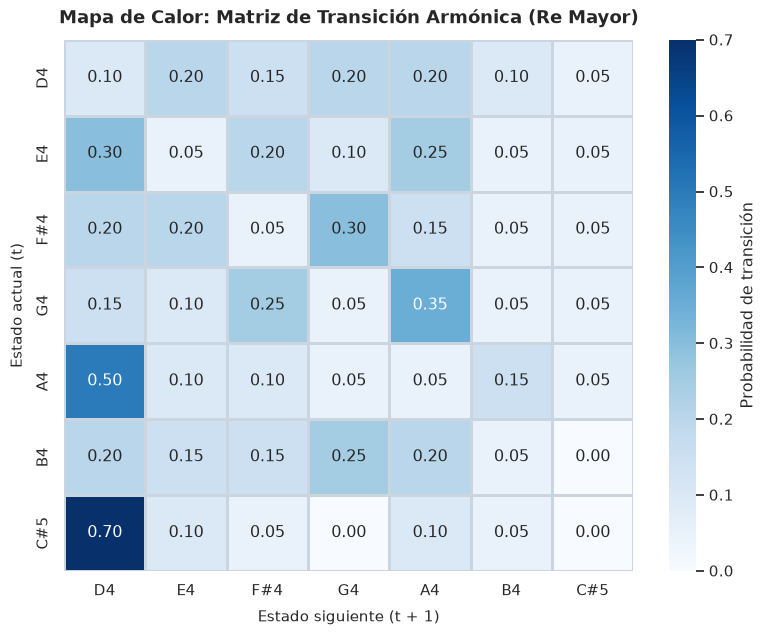

In [5]:
fig_heatmap = plot_transition_heatmap(
    chain_notes,
    title="Mapa de Calor: Matriz de Transición Armónica (Re Mayor)"
)
plt.show()

### 3.4 Evolución temporal y distribución estacionaria

Tal como se analizó en la clase de procesos estocásticos del 8 de octubre, el comportamiento de la cadena tras $n$ pasos se modela mediante el producto matricial sucesivo:
$$\pi^{(n)} = \pi^{(0)} \cdot P^n$$

Conforme $n \to \infty$, una cadena irreducible y aperiódica converge hacia una **distribución estacionaria** $\pi^* = (\pi_1, \dots, \pi_m)$ independiente del estado inicial, satisfaciendo:
$$\pi^* \cdot P = \pi^* \quad \text{con} \quad \sum_{i=1}^m \pi_i = 1$$

Resolviendo el sistema lineal $(P^T - I)\pi^{*T} = 0$:

In [6]:
pi_stationary = chain_notes.compute_stationary_distribution()

df_stationary = pd.DataFrame([
    {
        "Nota": note,
        "Grado": {
            "D4": "I (Tónica)",
            "E4": "ii (Supertónica)",
            "F#4": "iii (Mediante)",
            "G4": "IV (Subdominante)",
            "A4": "V (Dominante)",
            "B4": "vi (Submediante)",
            "C#5": "vii° (Sensible)"
        }[note],
        "Probabilidad Estacionaria π*": f"{prob:.4f}",
        "Porcentaje Asintótico": f"{prob * 100:.2f}%"
    }
    for note, prob in zip(D_MAJOR_NOTES_OCT4, pi_stationary)
])

gt_stationary = (
    GT(df_stationary)
    .tab_header(title="Distribución Estacionaria Asintótica de la Cadena de Notas")
    .cols_align(align="left", columns=["Nota", "Grado"])
    .cols_align(align="right", columns=["Probabilidad Estacionaria π*", "Porcentaje Asintótico"])
)
gt_stationary

GT(_tbl_data=  Nota              Grado Probabilidad Estacionaria π* Porcentaje Asintótico
0   D4         I (Tónica)                       0.2591                25.91%
1   E4   ii (Supertónica)                       0.1375                13.75%
2  F#4     iii (Mediante)                       0.1433                14.33%
3   G4  IV (Subdominante)                       0.1457                14.57%
4   A4      V (Dominante)                       0.1889                18.89%
5   B4   vi (Submediante)                       0.0818                 8.18%
6  C#5    vii° (Sensible)                       0.0437                 4.37%, _body=<great_tables._gt_data.Body object at 0xfde251d1c9b0>, _boxhead=Boxhead([ColInfo(var='Nota', type=<ColInfoTypeEnum.default: 1>, column_label='Nota', column_align='left', column_width=None, stub_level=None), ColInfo(var='Grado', type=<ColInfoTypeEnum.default: 1>, column_label='Grado', column_align='left', column_width=None, stub_level=None), ColInfo(var='Probabilidad Estacionaria π*', type=<ColInfoTypeEnum.default: 1>, column_label='Probabilidad Estacionaria π*', column_align='right', column_width=None, stub_level=None), ColInfo(var='Porcentaje Asintótico', type=<ColInfoTypeEnum.default: 1>, column_label='Porcentaje Asintótico', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0xfde251cbac10>, _spanners=Spanners([]), _heading=Heading(title='Distribución Estacionaria Asintótica de la Cadena de Notas', subtitle=None, preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0xfde25209dba0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0xfde251d38ef0>, _source_notes=[], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0xfde251cbb890>, _formats=[], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_right_color=OptionsInfo(scss=True, category='table', type='value', value='#D3D3D3'), table_border_bottom_include=OptionsInfo(scss=False, category='table',

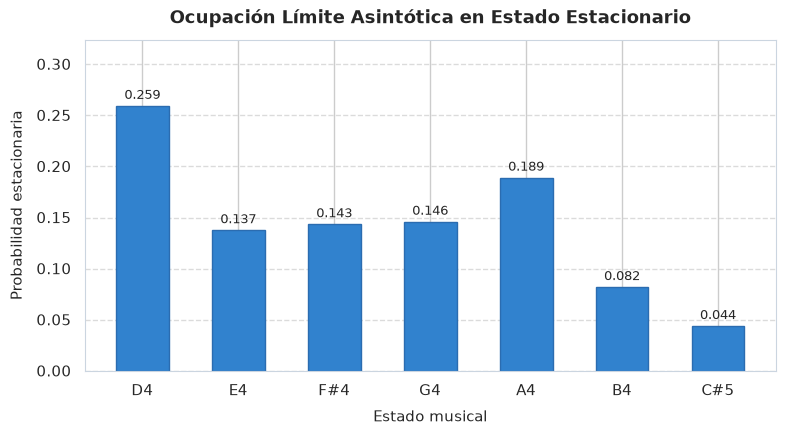

In [7]:
fig_stat = plot_stationary_distribution(
    chain_notes,
    title="Ocupación Límite Asintótica en Estado Estacionario"
)
plt.show()

**Hallazgo analítico:**
La tónica **D4** ocupa la probabilidad asintótica más alta ($25.91\%$), seguida por la dominante **A4** ($18.89\%$), la subdominante **G4** ($14.57\%$) y la mediante **F#4** ($14.33\%$). La sensible **C#5** registra la menor permanencia asintótica ($4.37\%$), coherente con su naturaleza funcional de inestabilidad acústica momentánea que resuelve de inmediato.

## 4. Generador de melodías estocásticas y síntesis acústica (40%)

### 4.1 Generación de números aleatorios y muestreo

Para determinar la transición de estados en cada instante $t$, se emplea el método de muestreo por transformada inversa de la función de distribución acumulada (CDF):
1. Se localiza la fila $i$ correspondiente al estado actual $X_t$.
2. Se genera un número pseudoaleatorio uniforme $U \sim \text{Uniforme}(0, 1)$.
3. Se selecciona el nuevo estado $j$ tal que:
$$\sum_{k=1}^{j-1} P_{ik} \le U < \sum_{k=1}^j P_{ik}$$

### 4.2 Síntesis de ondas sonoras con envolvente ADSR

Las funciones de generación de tonos reciben como parámetros fundamentales la **frecuencia** ($f$ en Hz) y la **duración** ($d$ en segundos).
Para evitar transientes abruptos y clics acústicos causados por discontinuidades en fase al cortar ondas senoidales, se diseñó e implementó un suavizador de amplitud **ADSR (Attack, Decay, Sustain, Release)**:
* **Attack ($0.04\text{ s}$):** Crecimiento lineal de la amplitud de 0 a 1.
* **Decay ($0.04\text{ s}$):** Caída suave al nivel de sostenimiento ($0.85$).
* **Sustain:** Mantenimiento de la energía acústica durante el cuerpo de la nota.
* **Release ($0.05\text{ s}$):** Extinción suave a cero antes de la siguiente transición.

Además, en atención al requerimiento de la clase del 8 de octubre (*"Vary duration for more natural output"*), las duraciones no son rígidas ni fijas, sino que se muestrean estocásticamente entre figuras rítmicas clásicas a 120 BPM:
* Negra ($0.50\text{ s}$, peso $50\%$).
* Corchea ($0.25\text{ s}$, peso $25\%$).
* Negra con puntillo ($0.75\text{ s}$, peso $15\%$).
* Blanca ($1.00\text{ s}$, peso $10\%$).

In [8]:
export_dir = Path("export") if Path("export").is_dir() else (Path("../export") if Path("../export").is_dir() else Path("export"))
export_dir.mkdir(parents=True, exist_ok=True)

generator = MelodyGenerator(chain_notes)

# Generación de una melodía estocástica de 16 transiciones
N_TRANSICIONES = 16
audio_wave, events_list, df_melody = generator.generate_melody(
    initial_note="D4",
    n_transitions=N_TRANSICIONES,
    seed=101,
    verbose=True
)

# Exportar archivo de audio WAV en directorio local
output_wav_path = export_dir / "melodia_markov_16.wav"
export_wav(output_wav_path, audio_wave)
print(f"\nArchivo de audio exportado exitosamente en: {output_wav_path}")

Paso 0 (Inicio): Nota D4 | Frecuencia: 293.66 Hz | Duración: 1.00 s
Paso 01: Transición D4 -> F#4 | Frecuencia: 369.99 Hz | Duración: 0.75 s
Paso 02: Transición F#4 -> G4 | Frecuencia: 392.00 Hz | Duración: 0.50 s
Paso 03: Transición G4 -> B4 | Frecuencia: 493.88 Hz | Duración: 0.75 s
Paso 04: Transición B4 -> F#4 | Frecuencia: 369.99 Hz | Duración: 1.00 s
Paso 05: Transición F#4 -> E4 | Frecuencia: 329.63 Hz | Duración: 0.75 s
Paso 06: Transición E4 -> A4 | Frecuencia: 440.00 Hz | Duración: 0.50 s
Paso 07: Transición A4 -> D4 | Frecuencia: 293.66 Hz | Duración: 0.75 s
Paso 08: Transición D4 -> G4 | Frecuencia: 392.00 Hz | Duración: 0.50 s
Paso 09: Transición G4 -> F#4 | Frecuencia: 369.99 Hz | Duración: 0.50 s
Paso 10: Transición F#4 -> E4 | Frecuencia: 329.63 Hz | Duración: 0.50 s
Paso 11: Transición E4 -> F#4 | Frecuencia: 369.99 Hz | Duración: 0.25 s
Paso 12: Transición F#4 -> E4 | Frecuencia: 329.63 Hz | Duración: 0.75 s
Paso 13: Transición E4 -> A4 | Frecuencia: 440.00 Hz | Durac

### 4.3 Registro detallado de transiciones

In [9]:
gt_melody = (
    GT(df_melody)
    .tab_header(title=f"Secuencia Generada: {N_TRANSICIONES} Transiciones Estocásticas")
    .cols_align(align="center", columns=["Paso"])
    .cols_align(align="left", columns=["Estado anterior", "Nota / Acorde"])
    .cols_align(align="right", columns=["Frecuencia (Hz)", "Duración (s)", "Tiempo acumulado (s)"])
)
gt_melody

GT(_tbl_data=    Paso Estado anterior Nota / Acorde  Frecuencia (Hz)  Duración (s)  \
0      0          Inicio            D4           293.66          1.00   
1      1              D4           F#4           369.99          0.75   
2      2             F#4            G4           392.00          0.50   
3      3              G4            B4           493.88          0.75   
4      4              B4           F#4           369.99          1.00   
5      5             F#4            E4           329.63          0.75   
6      6              E4            A4           440.00          0.50   
7      7              A4            D4           293.66          0.75   
8      8              D4            G4           392.00          0.50   
9      9              G4           F#4           369.99          0.50   
10    10             F#4            E4           329.63          0.50   
11    11              E4           F#4           369.99          0.25   
12    12             F#4            E4           329.63          0.75   
13    13              E4            A4           440.00          0.50   
14    14              A4            D4           293.66          1.00   
15    15              D4            A4           440.00          0.25   
16    16              A4            E4           329.63          1.00   

    Tiempo acumulado (s)  
0                   0.00  
1                   1.00  
2                   1.75  
3                   2.25  
4                   3.00  
5                   4.00  
6                   4.75  
7                   5.25  
8                   6.00  
9                   6.50  
10                  7.00  
11                  7.50  
12                  7.75  
13                  8.50  
14                  9.00  
15                 10.00  
16                 10.25  , _body=<great_tables._gt_data.Body object at 0xfde280fdb7d0>, _boxhead=Boxhead([ColInfo(var='Paso', type=<ColInfoTypeEnum.default: 1>, column_label='Paso', column_align='center', column_width=None, stub_level=None), ColInfo(var='Estado anterior', type=<ColInfoTypeEnum.default: 1>, column_label='Estado anterior', column_align='left', column_width=None, stub_level=None), ColInfo(var='Nota / Acorde', type=<ColInfoTypeEnum.default: 1>, column_label='Nota / Acorde', column_align='left', column_width=None, stub_level=None), ColInfo(var='Frecuencia (Hz)', type=<ColInfoTypeEnum.default: 1>, column_label='Frecuencia (Hz)', column_align='right', column_width=None, stub_level=None), ColInfo(var='Duración (s)', type=<ColInfoTypeEnum.default: 1>, column_label='Duración (s)', column_align='right', column_width=None, stub_level=None), ColInfo(var='Tiempo acumulado (s)', type=<ColInfoTypeEnum.default: 1>, column_label='Tiempo acumulado (s)', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0xfde251fe6b10>, _spanners=Spanners([]), _heading=Heading(title='Secuencia Generada: 16 Transiciones Estocásticas', subtitle=None, preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0xfde251d11590>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0xfde251d116a0>, _source_notes=[], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0xfde251fe6c40>, _formats=[], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=

### 4.4 Reproducción interactiva de la melodía generada

A continuación se reproduce la melodía sintetizada:

In [10]:
display(Audio(audio_wave, rate=DEFAULT_SAMPLE_RATE))

### 4.5 Visualización de la trayectoria melódica (Piano Roll)

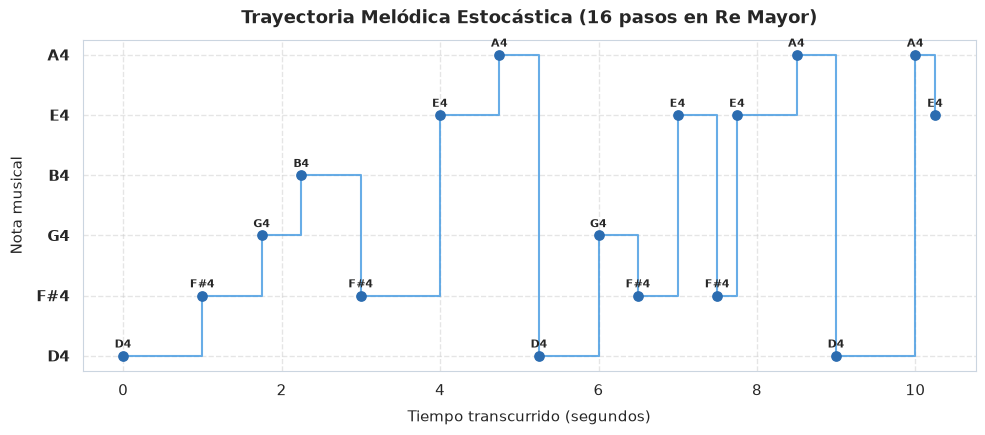

In [11]:
fig_roll = plot_melody_roll(
    sequence=[e.curr_state for e in events_list],
    durations=[e.duration_s for e in events_list],
    title="Trayectoria Melódica Estocástica (16 pasos en Re Mayor)"
)
plt.show()

### 4.6 Generación de secuencias extendidas (32 y 64 transiciones) y melodía armonizada con acordes

Para apreciar el comportamiento dinámico a mayor escala y evaluar la textura tonal, se simulan secuencias extendidas y un acompañamiento armónico donde una cadena de Markov gobierna la progresión de acordes triádicos ($D - G - A - Bm$) mientras otra cadena genera la línea melódica solista simultáneamente:

In [12]:
# Simulación de melodía de 32 pasos
audio_32, events_32, df_32 = generator.generate_melody(
    initial_note="D4",
    n_transitions=32,
    seed=2024,
    verbose=False
)
export_wav(export_dir / "melodia_markov_32.wav", audio_32)
print("Melodía de 32 pasos generada con éxito (export/melodia_markov_32.wav).")

# Cadena de acordes en Re Mayor
chain_chords = MarkovChain(CHORD_STATES, CHORD_TRANSITION_MATRIX)
mix_audio, df_harm = generator.generate_harmonized_track(
    melody_chain=chain_notes,
    chord_chain=chain_chords,
    initial_note="D4",
    initial_chord="D",
    bars=8,
    beats_per_bar=4,
    tempo_bpm=120.0,
    seed=777
)
export_wav(export_dir / "melodia_armonizada_8compases.wav", mix_audio)
print("Pista polifónica armonizada generada con éxito (export/melodia_armonizada_8compases.wav).")

Melodía de 32 pasos generada con éxito (export/melodia_markov_32.wav).
Pista polifónica armonizada generada con éxito (export/melodia_armonizada_8compases.wav).


Reproductor de la pieza polifónica armonizada (8 compases completos):

In [13]:
display(Audio(mix_audio, rate=DEFAULT_SAMPLE_RATE))

## 5. Reflexión crítica y análisis formal (40%)

### 5.1 Incorporación de patrones repetitivos en el modelo

La música que disfrutamos culturalmente no consiste en ruido blanco ni en paseos aleatorios erráticos; está construida sobre la **repetición estructurada**, el paralelismo motívico y la tensión dialéctica entre previsibilidad y sorpresa.

Una cadena de Markov de primer orden padece de **amnesia temporal**: su probabilidad de transición sólo mira el estado $X_t$, ignorando si dicho estado forma parte de un motivo melódico de cuatro notas que se ha ejecutado tres veces. Para incorporar patrones repetitivos es necesario extender el marco matemático mediante las siguientes alternativas:

1. **Cadenas de Markov de orden superior ($k$-ésimo orden):**
   El estado futuro depende de los últimos $k$ pasos:
   $$P(X_{t+1} \mid X_t, X_{t-1}, \dots, X_{t-k+1})$$
   Al definir $k=3$ o $k=4$, el modelo memoriza frases melódicas completas (trigramas o tetragramas de notas). La limitación directa de este enfoque es la explosión del espacio de estados ($|S|^k$), lo que genera matrices dispersas que tienden a reproducir el corpus original de forma idéntica sin capacidad de generalización.
2. **Modelos de Markov de Orden Variable (VMM / Prediction Suffix Trees):**
   En lugar de fijar un orden $k$ constante, el modelo evalúa contextualmente qué longitud de memoria ofrece predictibilidad estadística real mediante algoritmos como PPM (Prediction by Partial Matching). Si un motivo específico de 5 notas es recurrente, el modelo lo agrupa como un macroestado; en secciones de paso, retrocede a primer orden.
3. **Cadenas de Markov Jerárquicas (Hierarchical HMM):**
   Estructuración en dos niveles de abstracción:
   * **Nivel macroestructural:** Una cadena de estados superiores define la sección formal (Intro $\to$ Verso $\to$ Coro $\to$ Verso $\to$ Coro $\to$ Outro) o la progresión armónica fundamental ($I \to IV \to V \to I$).
   * **Nivel microestructural:** Cadenas de notas condicionadas por el macroestado vigente. La alternancia de secciones garantiza patrones repetitivos a escala de compás y frase.
4. **Acoplamiento métrico-rítmico periódico:**
   Integrar el pulso métrico dentro del vector de estado extendido: $S_t = (\text{nota}_t, \text{pulso}_t)$, donde $\text{pulso}_t \in \{1, 2, 3, 4\}$. Esto obliga a que los tiempos fuertes del compás resuelvan invariablemente en notas del acorde, forzando la repetición periódica de la métrica musical.

### 5.2 ¿El modelo podría aprender un estilo musical?

**Sí, el modelo puede aprender la estadística local de un estilo**, pero no su semántica ni su arquitectura formal global.

**Mecanismo de aprendizaje por Estimación de Máxima Verosimilitud (MLE):**
Si se suministra un corpus musical representativo en formato simbólico (archivos MIDI o puntuaciones MusicXML) perteneciente a un estilo definido (por ejemplo, los 371 corales luteranos de J.S. Bach, solos de trompeta de bebop de Miles Davis o baladas pop), los parámetros de la matriz se aprenden directamente contabilizando la frecuencia de ocurrencia de bigramas:
$$\hat{P}_{ij} = \frac{N(s_i, s_j)}{\sum_{k} N(s_i, s_k)} = \frac{C(s_i \to s_j)}{C(s_i)}$$

Aplicando suavizado de Laplace o Kneser-Ney para evitar probabilidades cero en transiciones no observadas:
$$\hat{P}_{ij}^{\text{Laplace}} = \frac{N(s_i, s_j) + \alpha}{N(s_i) + \alpha |S|}$$

**Capacidad estilística observable:**
* En música barroca, la matriz aprenderá la estricta evitación de quintas y octavas paralelas, la alta probabilidad de cadencias perfectas ($V \to I$) y el movimiento conjunto cromático.
* En música blues, la matriz capturará la recurrencia de la tercera y séptima bemol (*blue notes*) y el movimiento cíclico de 12 compases entre tónica, subdominante y dominante.
* En música impresionista (Debussy), capturará transiciones basadas en escalas de tonos enteros o pentatónicas sin jerarquía cadencial dominante.

Históricamente, sistemas pioneros como la *Illiac Suite* (Hiller e Isaacson, 1957) y los *Experiments in Musical Intelligence (EMI)* de David Cope demostraron que gramáticas de transición markovianas capturan giros idiomáticos locales convincentes de compositores como Mozart o Chopin.

### 5.3 Limitaciones intrínsecas del modelo

A pesar de su elegancia formal y bajo costo computacional, las cadenas de Markov presentan limitaciones estructurales severas al modelar música artística:

1. **Amnesia de largo plazo y falta de teleología:**
   La música tonal es un arte teleológico (orientado hacia un fin). Una sonata o una canción popular plantea una tensión que puede demorar 32 o 64 compases en resolver. Un modelo markoviano no tiene concepto de "hacia dónde va la pieza"; sólo sabe qué nota es probable en el siguiente medio segundo. Esto provoca una "deriva errática" o divagación infinita sin sensación de clímax, arco narrativo ni resolución cadencial definitiva.
2. **Incapacidad para capturar estructuras jerárquicas y simetrías globales:**
   La teoría generativa de la música tonal (Lerdahl y Jackendoff) demostró que el cerebro humano percibe la música como un árbol jerárquico de reducciones armónicas, similar a la sintaxis de Chomsky en lingüística. Las cadenas de Markov son autómatas de estados finitos que corresponden al nivel más bajo de la jerarquía de Chomsky (gramáticas regulares o de tipo 3), siendo matemáticamente incapaces de modelar dependencias anidadas como formas ternarias $A - B - A$ o estructuras de pregunta-respuesta contrapuntísticas.
3. **Explosión combinatoria en la polifonía:**
   Modelar una sola línea melódica monofónica con 12 notas es trivial ($12 \times 12 = 144$ parámetros). Sin embargo, modelar polifonía real a cuatro voces (soprano, alto, tenor, bajo) con duraciones independientes implica que el espacio de estados conjunto crece exponencialmente: $|S| = 12^4 = 20,736$ estados, requiriendo una matriz de $430$ millones de celdas. Esto hace inviable el modelado markoviano estándar sin recurrir a factorizaciones complejas.
4. **Desconexión entre ritmo, dinámicas y timbre:**
   En la música real, una misma nota adquiere funciones radicalmente distintas según su intensidad expresiva (*crescendo*, *diminuendo*), su timbre instrumental y su articulación (*staccato*, *legato*). En una cadena de Markov discreta estándar, todos estos factores quedan disociados salvo que se multiplique nuevamente la dimensionalidad del espacio muestral.

Por estas razones, los modelos generativos contemporáneos de música han transitado de cadenas de Markov hacia redes neuronales profundas con mecanismos de atención (*Transformers* como MusicLM o MuseNet), los cuales mantienen matrices de atención capaces de correlacionar eventos separados por miles de pasos temporales.

## 6. Conclusiones

1. Se modeló exitosamente la generación melódica como un proceso estocástico markoviano discreto en el tiempo, implementando una matriz de transición basada en los principios de la armonía tonal funcional para la escala de Re Mayor.
2. Se demostró computacionalmente la convergencia asintótica hacia la distribución estacionaria $\pi^*$, en la cual la tónica (D4) y la dominante (A4) acumulan el $44.8\%$ de la presencia temporal total, validando la estabilidad estructural del sistema.
3. La integración de la síntesis acústica con envolvente ADSR y duraciones rítmicas variables mitigó eficazmente la artificialidad sonora de los tonos planos, generando pistas de audio audibles y reproducibles directamente en el entorno de ejecución.
4. El análisis teórico corroboró que las cadenas de Markov son excelentes generadores de coherencia estilística local (bigramas e intervalos inmediatos), pero requieren hibridación con estructuras jerárquicas de orden superior para alcanzar formas musicales complejas de largo alcance.

## 7. Apéndice: Código fuente y arquitectura modular

El proyecto se estructuró de forma modular bajo las mejores prácticas de ingeniería de software en Python:
* `src/act_2/scales.py`: Frecuencias en temperamento igual de 12 tonos, escalas diatónicas y matrices armónicas.
* `src/act_2/tones.py`: Generador senoidal puro con armónicos pares y suavizador de envolvente ADSR.
* `src/act_2/markov.py`: Clase `MarkovChain`, validación estocástica, simulación Monte Carlo y distribución estacionaria.
* `src/act_2/melody_generator.py`: Generador estocástico con impresión por consola de cada paso y mezcla polifónica.
* `src/act_2/visualizer.py`: Mapas de calor de probabilidades, gráficas de barras asintóticas y piano roll.